# B1 / B5 · Plan model, policy evaluator and baselines (live session)

PLAN §7 B1 and B5. Stream B owns it. Builds the weekly planning problem and the yardsticks the GA will be measured against:

1. **Load**: member scores, the rules' allowed offers, the live offer catalogue, staff roster and limits.
2. **Instance**: one row per option (member, offer, channel) with cost, staff minutes and estimated uplift.
3. **Objective**: value = uplift × monthly fee × H − cost, with H = 6 months (decision #2).
4. **Feasibility**: budget, staff minutes, trainer minutes, stock, one contact per member, allowed options only.
5. **Policy evaluator**: grades any plan with the scenario's hidden truth (`true_uplift`, `true_churn`).
6. **Baselines**: contact-all and risk-top-k with the playbook's top offer (decision #3), greedy-uplift.
7. **First E4 numbers.**

Candidates are the rules' `allowed` offers only: playbook proposals that no guardrail blocked (HANDOFFS #6).
Estimated uplift comes from A's T-learner until the CBR (B4) replaces it. `true_uplift` and `true_churn` are used
**only** in the evaluator, never to choose a plan.

Everything is imported from `anchorai`. Nothing is written to the app DB. It reads the built data
(`uv run anchorai setup`).

## 1. Load

Reads the live catalogue, roster and limits from the app DB (`catalog.py`), not `offers.parquet`, so admin edits count.
Rules run on every member with the active rule version; `drop_inactive` removes offers an admin switched off.

**Look for:** 4,000 members; about 1,200 with an allowed offer; budget $1,500 and 2,160 staff minutes;
only `staff1` has the `trainer` skill.

In [1]:
from pathlib import Path

import pandas as pd
from anchorai import catalog
from anchorai.config import get_settings
from anchorai.db.session import get_engine
from anchorai.discovery.scores import load_scores
from anchorai.reasoning.engine import run_many
from anchorai.reasoning.service import active_rules, all_facts, drop_inactive
from anchorai.scenario.tables import read_tables
from sqlmodel import Session

SEED = get_settings().anchorai_seed
H = 6  # value horizon in months (decision #2)
FIG, RES = Path("figures"), Path("results")

tables = read_tables()
scores = load_scores().set_index("member_id")
session = Session(get_engine())
offers = {o.offer_id: o for o in catalog.list_offers(session, active_only=True)}
staff = catalog.list_staff(session)
limits = catalog.get_constraints(session)
version, rules = active_rules(session)
outcomes = {
    m: drop_inactive(session, o) for m, o in run_many(rules, all_facts(session)).items()
}

print(
    f"{len(scores)} members | rule version {version}, {len(rules)} rules | "
    f"{sum(bool(o.allowed) for o in outcomes.values())} members with an allowed offer"
)
print(limits)
display(pd.DataFrame([s.model_dump() for s in staff]).set_index("username"))
pd.DataFrame([o.model_dump() for o in offers.values()]).set_index("offer_id")

4000 members | rule version 1, 29 rules | 1227 members with an allowed offer
default_budget=1500.0 default_staff_minutes=2160 max_contacts_per_member_per_30d=1 max_offers_per_member_per_90d=2


,weekly_hours,skills,user_id,full_name
username,,,,
staff1,20.0,"[trainer, calls]",3,Sam Staff
staff2,16.0,[calls],4,Jordan Staff


,name,cost,staff_minutes,inventory,channels,eligibility,required_skill,active
offer_id,,,,,,,,
checkin_message,Personal check-in message,0.0,5,NaN,"[sms, email, call]",Any active member,,True
class_pass,Bring-a-friend class pass,15.0,10,100.0,"[sms, email, call]",Any active member,,True
discount_1m,One month at 20% off,12.0,15,NaN,"[email, call]",Month-to-month members only,,True
free_pt_session,Free personal training session,40.0,60,40.0,"[call, in_person]",Members without PT in the last 90 days,trainer,True


## 2. Instance

One row per **option**: a member, one of their allowed offers and the channel the playbook chose. `rank` 0 is the
playbook's top offer. `est_uplift` is A's T-learner estimate for now; `value` = est_uplift × monthly fee × H − cost.
"No contact" has no row: it is the default, worth /usr/bin/zsh.

**Look for:** about 2,470 options for 1,227 members, at most 4 per member. Which offers the estimates think are worth
their cost (`worth_it` = share of options with value > 0).

In [2]:
from anchorai.scenario.tables import generated_dir

est = pd.read_parquet(generated_dir() / "uplift_tlearner.parquet").set_index(
    ["member_id", "offer_id"]
)["uplift"]
catalogue = pd.DataFrame([o.model_dump() for o in offers.values()]).set_index(
    "offer_id"
)

options = pd.DataFrame(
    [
        {
            "member_id": m,
            "offer_id": p.offer_id,
            "channel": p.channel,
            "rule_id": p.rule_id,
            "rank": i,
        }
        for m, o in outcomes.items()
        for i, p in enumerate(o.allowed)
    ]
)
options = options.join(
    catalogue[["cost", "staff_minutes", "required_skill"]], on="offer_id"
)
options = options.join(
    scores[["churn_prob", "risk_band", "monthly_value"]], on="member_id"
)
options["est_uplift"] = est.reindex(
    pd.MultiIndex.from_frame(options[["member_id", "offer_id"]])
).to_numpy()
options["value"] = (
    options["est_uplift"] * options["monthly_value"] * H - options["cost"]
)

print(
    f"{len(options)} options for {options['member_id'].nunique()} members "
    f"({options.groupby('member_id').size().max()} at most per member)"
)
options.groupby("offer_id").agg(
    options=("member_id", "size"),
    est_uplift=("est_uplift", "mean"),
    value=("value", "mean"),
    worth_it=("value", lambda v: (v > 0).mean()),
).round(3)

2469 options for 1227 members (4 at most per member)


,options,est_uplift,value,worth_it
offer_id,,,,
checkin_message,739,0.059,24.067,0.704
class_pass,185,0.144,43.325,0.881
discount_1m,747,0.112,36.554,0.746
free_pt_session,798,0.265,70.829,0.876


## 3. Objective

What the planner maximises: the dollar value it *believes* a plan has. The GA will call this as its fitness.

**Look for:** giving every member their top offer would cost far more than the 1,500 budget and the 2,160 staff
minutes. That gap is why choosing matters.

In [3]:
def plan_value(plan: pd.DataFrame) -> float:
    """What the planner believes a plan is worth in dollars: Σ est_uplift × fee × H − cost."""
    return float(plan["value"].sum())


top = options[options["rank"] == 0]
print(
    f"if every member got their playbook top offer: {len(top)} contacts, "
    f"${top['cost'].sum():,.0f}, {top['staff_minutes'].sum():,} staff minutes, value ${plan_value(top):,.0f}"
)

if every member got their playbook top offer: 1227 contacts, $30,198, 46,970 staff minutes, value $56,481


## 4. Feasibility

A plan is feasible only if it breaks no limit: allowed options only, one contact per member, budget, staff minutes,
trainer minutes (free PT needs a trainer, and only trainers' hours count) and stock. Contact fatigue and offer caps are
already enforced by guardrails G01 and G02, so they never reach the options table.

**Look for:** the "all top offers" plan breaks budget, staff minutes, trainer minutes and PT stock; the empty plan
breaks nothing (`{}`).

In [4]:
TRAINER_MINUTES = 60 * sum(s.weekly_hours for s in staff if "trainer" in s.skills)


def violations(
    plan: pd.DataFrame, budget: float, staff_minutes: int
) -> dict[str, float]:
    """Every broken limit and by how much; an empty dict means the plan is feasible."""
    over = {
        "not an allowed option": (~plan.index.isin(options.index)).sum(),
        "members contacted twice": plan["member_id"].duplicated().sum(),
        "budget ($)": plan["cost"].sum() - budget,
        "staff minutes": plan["staff_minutes"].sum() - staff_minutes,
        "trainer minutes": plan.loc[
            plan["required_skill"] == "trainer", "staff_minutes"
        ].sum()
        - TRAINER_MINUTES,
    }
    used = plan["offer_id"].value_counts()
    for offer_id, o in offers.items():
        if o.inventory is not None:
            over[f"{offer_id} stock"] = used.get(offer_id, 0) - o.inventory
    return {k: float(v) for k, v in over.items() if v > 0}


print("trainer minutes per week:", TRAINER_MINUTES)
print(
    "all top offers:",
    violations(top, limits.default_budget, limits.default_staff_minutes),
)
print(
    "empty plan:",
    violations(options.iloc[:0], limits.default_budget, limits.default_staff_minutes),
)

trainer minutes per week: 1200.0
all top offers: {'budget ($)': 28698.0, 'staff minutes': 44810.0, 'trainer minutes': 42900.0, 'free_pt_session stock': 695.0}
empty plan: {}


## 5. Policy evaluator

Grades any plan with the scenario's hidden truth: `true_churn.event_churn` for members left alone and
`true_uplift` for the contacted ones (HANDOFFS #26). **Only used to grade, never to choose.**
`estimated_extra` is what the plan's own estimates claimed, so the two can be compared.

**Look for:** about 2,660 of 4,000 members stay with no contact. `extra_retained` (truth) vs `estimated_extra`
(T-learner): how far off the estimates are.

In [5]:
truth = tables["true_uplift"].set_index(["member_id", "offer_id"])["uplift"]
no_contact = 1 - tables["true_churn"].set_index("member_id")["event_churn"]


def evaluate(plan: pd.DataFrame) -> dict[str, float]:
    """Grade a plan with the scenario's hidden truth. Never used to choose a plan."""
    gain = truth.reindex(
        pd.MultiIndex.from_frame(plan[["member_id", "offer_id"]])
    ).to_numpy()
    spend, minutes, extra = plan["cost"].sum(), plan["staff_minutes"].sum(), gain.sum()
    return {
        "contacts": len(plan),
        "spend": spend,
        "staff_minutes": minutes,
        "members_retained": no_contact.sum() + extra,
        "extra_retained": extra,
        "estimated_extra": plan["est_uplift"].sum(),
        "per_1000_dollars": 1000 * extra / spend if spend else float("nan"),
        "per_staff_hour": 60 * extra / minutes if minutes else float("nan"),
    }


print(
    f"no contact at all: {no_contact.sum():,.0f} of {len(no_contact)} members expected to stay next month"
)
pd.Series(evaluate(top)).round(2)

no contact at all: 2,661 of 4000 members expected to stay next month


contacts             1227.00
spend               30198.00
staff_minutes       46970.00
members_retained     2848.75
extra_retained        187.49
estimated_extra       208.09
per_1000_dollars        6.21
per_staff_hour          0.24
dtype: float64

## 6. Baselines

All three fill the plan the same way (`fill`: walk the options in order, take each one that still fits every limit),
so they differ only in the **order**:
- **contact-all:** playbook top offer, members in random order (decision #3)
- **risk-top-k:** playbook top offer, highest churn risk first (decision #3)
- **greedy-uplift:** any allowed option with value > 0, best value per share of budget and staff time first

**Look for:** `violations` = 0 for all three. Which limit runs out first (compare `spend` with ,500 and
`staff_minutes` with 2,160). How the three compare on `extra_retained`.

In [6]:
def fill(ordered: pd.DataFrame, budget: float, staff_minutes: int) -> pd.DataFrame:
    """Walk the options in order and take each one that still fits every limit (first fit)."""
    stock = {k: o.inventory for k, o in offers.items() if o.inventory is not None}
    spent = used = trainer = 0.0
    taken, keep = set(), []
    for i, r in zip(ordered.index, ordered.itertuples()):
        is_trainer = r.required_skill == "trainer"
        if (
            r.member_id in taken
            or spent + r.cost > budget
            or used + r.staff_minutes > staff_minutes
            or (is_trainer and trainer + r.staff_minutes > TRAINER_MINUTES)
            or stock.get(r.offer_id, 1) < 1
        ):
            continue
        taken.add(r.member_id)
        spent += r.cost
        used += r.staff_minutes
        trainer += r.staff_minutes if is_trainer else 0
        if r.offer_id in stock:
            stock[r.offer_id] -= 1
        keep.append(i)
    return ordered.loc[keep]


def contact_all(budget, staff_minutes, seed=SEED):
    """Playbook top offer, members in random order."""
    return fill(top.sample(frac=1, random_state=seed), budget, staff_minutes)


def risk_top_k(budget, staff_minutes, seed=SEED):
    """Playbook top offer, highest churn risk first."""
    return fill(
        top.sort_values(["churn_prob", "member_id"], ascending=[False, True]),
        budget,
        staff_minutes,
    )


def greedy_uplift(budget, staff_minutes, seed=SEED):
    """Any allowed option worth more than it costs, best value per share of budget and staff time first."""
    c = options[options["value"] > 0]
    density = c["value"] / (c["cost"] / budget + c["staff_minutes"] / staff_minutes)
    return fill(
        c.assign(density=density).sort_values(
            ["density", "member_id"], ascending=[False, True]
        ),
        budget,
        staff_minutes,
    )


POLICIES = {
    "contact-all": contact_all,
    "risk-top-k": risk_top_k,
    "greedy-uplift": greedy_uplift,
}
B, M = limits.default_budget, limits.default_staff_minutes
pd.DataFrame(
    {
        name: {**evaluate(p := f(B, M)), "violations": len(violations(p, B, M))}
        for name, f in POLICIES.items()
    }
).T.round(2)

,contacts,spend,staff_minutes,members_retained,extra_retained,estimated_extra,per_1000_dollars,per_staff_hour,violations
contact-all,185.0,1079.0,2160.0,2672.14,10.89,8.66,10.09,0.30,0.0
risk-top-k,156.0,1208.0,2160.0,2675.63,14.37,18.32,11.90,0.40,0.0
greedy-uplift,409.0,165.0,2160.0,2689.19,27.94,62.37,169.33,0.78,0.0


## 7. First E4 numbers

E4 varies **both** limits: five budgets at three staff levels (today's roster of 36 h, double it, and C's E6 setting of
120 h), five seeds each (only contact-all is random). With today's roster staff time runs out before money, so a
budget axis alone would be flat. Saved to `results/b5_e4_baselines.csv` and `figures/b5_e4_baselines.png`.

**Look for:** 0 violations (the assert). At 2,160 minutes the lines are flat: more budget buys nothing. With more staff
the lines rise until time or money runs out. The gap between greedy-uplift and the other two at each setting is what
the GA must beat later. `per_staff_hour` is the fairer efficiency measure when spend is near /usr/bin/zsh.

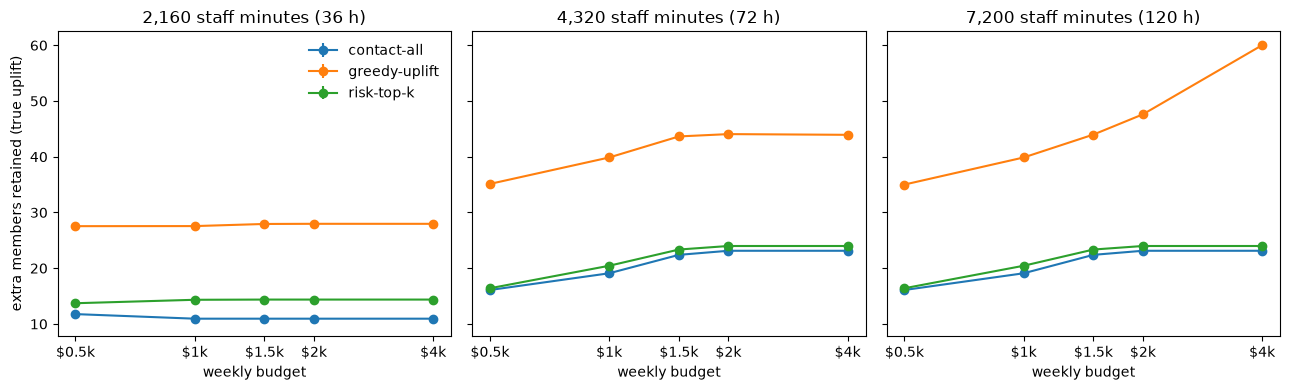

contacts   spend  staff_minutes  \
policy        staff_limit budget                                    
contact-all   2160        500        302.0   492.6         2160.0   
                          1000       192.2   992.6         2160.0   
                          1500       183.6  1074.8         2160.0   
                          2000       183.6  1074.8         2160.0   
                          4000       183.6  1074.8         2160.0   
              4320        500        448.2   492.6         2891.0   
                          1000       468.0   992.6         3539.0   
                          1500       504.4  1494.8         3976.0   
                          2000       512.0  1598.0         4070.0   
                          4000       512.0  1598.0         4070.0   
              7200        500        448.2   492.6         2891.0   
                          1000       468.0   992.6         3539.0   
                          1500       504.4  1494.8         3976.0   
                          2000       512.0  1598.0         4070.0   
                          4000       512.0  1598.0         4070.0   
greedy-uplift 2160        500        432.0     0.0         2160.0   
                          1000       426.0    36.0         2160.0   
                          1500       409.0   165.0         2160.0   
                          2000       401.0   231.0         2160.0   
                          4000       378.0   396.0         2160.0   
              4320        500        560.0   489.0         3185.0   
                          1000       601.0   993.0         3780.0   
                          1500       635.0  1491.0         4320.0   
                          2000       604.0  1686.0         4320.0   
                          4000       588.0  1800.0         4320.0   
              7200        500        561.0   498.0         3205.0   
                          1000       601.0   993.0         3780.0   
                          1500       642.0  1500.0         4370.0   
                          2000       683.0  1998.0         4975.0   
                          4000       791.0  3984.0         7200.0   
risk-top-k    2160        500        298.0   492.0         2160.0   
                          1000       182.0   998.0         2160.0   
                          1500       156.0  1208.0         2160.0   
                          2000       156.0  1208.0         2160.0   
                          4000       156.0  1208.0         2160.0   
              4320        500        447.0   492.0         2905.0   
                          1000       470.0   998.0         3600.0   
                          1500       505.0  1493.0         4000.0   
                          2000       512.0  1598.0         4070.0   
                          4000       512.0  1598.0         4070.0   
              7200        500        447.0   492.0         2905.0   
                          1000       470.0   998.0         3600.0   
                          1500       505.0  1493.0         4000.0   
                          2000       512.0  1598.0         4070.0   
                          4000       512.0  1598.0         4070.0   

                                  extra_retained  per_staff_hour  extra_sd  
policy        staff_limit budget                                            
contact-all   2160        500              11.77            0.33      0.43  
                          1000             10.94            0.30      0.63  
                          1500             10.95            0.30      0.44  
                          2000             10.95            0.30      0.44  
                          4000             10.95            0.30      0.44  
              4320        500              16.09            0.33      0.13  
                          1000             19.09            0.32      0.23  
                          1500             22.40            0.34      0.18  
                    

In [7]:
import matplotlib.pyplot as plt

BUDGETS = [500, 1000, 1500, 2000, 4000]
STAFF_LEVELS = [
    M,
    2 * M,
    7200,
]  # today's roster (36 h), double it, C's E6 setting (120 h)
SEEDS = range(5)

rows = []
for staff_minutes in STAFF_LEVELS:
    for budget in BUDGETS:
        for seed in SEEDS:
            for name, f in POLICIES.items():
                plan = f(budget, staff_minutes, seed)
                rows.append(
                    {
                        "policy": name,
                        "staff_limit": staff_minutes,
                        "budget": budget,
                        "seed": seed,
                        **evaluate(plan),
                        "violations": len(violations(plan, budget, staff_minutes)),
                    }
                )
runs = pd.DataFrame(rows)
assert runs["violations"].eq(0).all(), "a baseline produced an infeasible plan"

FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)
keys = ["policy", "staff_limit", "budget"]
summary = runs.groupby(keys)[
    ["contacts", "spend", "staff_minutes", "extra_retained", "per_staff_hour"]
].mean()
summary["extra_sd"] = runs.groupby(keys)["extra_retained"].std()
summary.round(2).to_csv(RES / "b5_e4_baselines.csv")

fig, axes = plt.subplots(1, len(STAFF_LEVELS), figsize=(13, 4), sharey=True)
for ax, staff_minutes in zip(axes, STAFF_LEVELS):
    level = summary.xs(staff_minutes, level="staff_limit").reset_index()
    for name, g in level.groupby("policy"):
        ax.errorbar(
            g["budget"],
            g["extra_retained"],
            yerr=g["extra_sd"].fillna(0),
            marker="o",
            label=name,
        )
    ax.set_xscale("log")
    ax.minorticks_off()
    ax.set_xticks(BUDGETS, [f"${b / 1000:g}k" for b in BUDGETS])
    ax.set_xlabel("weekly budget")
    ax.set_title(f"{staff_minutes:,} staff minutes ({staff_minutes // 60} h)")
axes[0].set_ylabel("extra members retained (true uplift)")
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "b5_e4_baselines.png")
plt.show()
summary.round(2)